# **Customer Segmentation & Churn Analytics**

**Day - 1**

**Step 1** - Import Dataset  

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

df = pd.read_csv('/content/European_Bank (1).csv')

**Step 2** - Check Dataset Preview

In [ ]:
df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**Step 3** - Check Shape

In [ ]:
df.shape


(10000, 14)

**Step 4** - Check Data Types

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


**Step 5** - Check Sum of Missing Values in a dataset

In [ ]:
df.isnull().sum()

,0
Year,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


Step 6 - Check Sum of Duplicate Values in a dataset

In [ ]:
df.duplicated().sum()

np.int64(0)

**Step 7** - Check Unique Categories

In [ ]:
print(df["Geography"].unique())

print(df["Gender"].unique())

print(df["Exited"].unique())

['France' 'Spain' 'Germany']
['Female' 'Male']
[1 0]


# **Day 2 - Data Cleaning & Feature Engineering (Segmentation Creation).**

**Step 8**: Create a Working Copy

In [ ]:
df2 = df.copy()

**Step 9** - Preview the dataset

In [ ]:
df2.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**Step 10** - Remove the unneseccary columns using drop function

In [ ]:
df2.drop(['Year', 'CustomerId', 'Surname'], axis=1, inplace=True)

**Step 11** - Preview the dataset

In [ ]:
df2.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='object')

**Step 12** - Create Age Groups

In [ ]:
def age_group(age):

    if age < 30:
        return "<30"

    elif age <= 45:
        return "30-45"

    elif age <= 60:
        return "46-60"

    else:
        return "60+"

df2['AgeGroup'] = df2['Age'].apply(age_group)

**Step 13** - Preview The Dataset

In [ ]:
df2[['Age','AgeGroup']].head(10)

,Age,AgeGroup
0,42,30-45
1,41,30-45
2,42,30-45
3,39,30-45
4,43,30-45
5,44,30-45
6,50,46-60
7,29,<30
8,44,30-45
9,27,<30


**Step 14** - Check Age Group Distribution

In [ ]:
df2['AgeGroup'].value_counts()

,count
AgeGroup,
30-45,6248
46-60,1647
<30,1641
60+,464


# **Credit Score Bands**

In [ ]:
def credit_band(score):

    if score < 580:
        return "Low"

    elif score < 670:
        return "Medium"

    else:
        return "High"

df2['CreditScoreBand'] = df2['CreditScore'].apply(credit_band)

**Step 15** - Preview The Dataset

In [ ]:
df2[['CreditScore','CreditScoreBand']].head(10)

,CreditScore,CreditScoreBand
0,619,Medium
1,608,Medium
2,502,Low
3,699,High
4,850,High
5,645,Medium
6,822,High
7,376,Low
8,501,Low
9,684,High


**Step 16** - Check Credit Score Band Distribution

In [ ]:
df2['CreditScoreBand'].value_counts()

,count
CreditScoreBand,
High,4307
Medium,3331
Low,2362


# **Create Tenure Group**

In [ ]:
def tenure_group(tenure):

    if tenure <= 3:
        return "New"

    elif tenure <= 7:
        return "Mid-Term"

    else:
        return "Long-Term"

df2['TenureGroup'] = df2['Tenure'].apply(tenure_group)

**Step 17** - Preview The Dataset

In [ ]:
df2[['Tenure','TenureGroup']].head()

,Tenure,TenureGroup
0,2,New
1,1,New
2,8,Long-Term
3,1,New
4,2,New


**Step 18** - Check the Tenure Distribution using count

In [ ]:
df2['TenureGroup'].value_counts()

,count
TenureGroup,
Mid-Term,3996
New,3505
Long-Term,2499


**Step 19** - Count Total Customers

In [ ]:
len(df2)

10000

**Step 20** - Total Customers Who Left/Exited

In [ ]:
import pandas as pd

df2['Exited'].sum()

np.int64(2037)

# **Preparing KPIS**

**Step 21** - Calculating Overall Churn Rate for Exited customers

In [ ]:
(df2['Exited'].sum() / len(df2)) * 100

np.float64(20.369999999999997)

Overall Churn Rate = 20.37%

**Step 22** - Calculating churn rate based on countries

In [ ]:
df2.groupby('Geography')['Exited'].mean()*100

,Exited
Geography,
France,16.154767
Germany,32.443204
Spain,16.673395


**Output**

Country	Churn Rate (%)
France	16.15%
Germany	32.44%
Spain	16.67%


*Key Insights - Based on the Calcultion we can analyse that germany has highest churn rate and France has the lowest whereas we can also analyse that Spain do has moderate one.*

**Step 23** - Calculating Churn Rate Based On Gender

In [ ]:
df2.groupby('Gender')['Exited'].mean()*100

,Exited
Gender,
Female,25.071539
Male,16.455928


Gender	Churn Rate (%)
Female	25.07%
Male	16.46%

*Key Insights - Female has more churn rate as compare to mens*

**Step 24** - Calculating the percentage of activeusers

In [ ]:
df2.groupby('IsActiveMember')['Exited'].mean() * 100

,Exited
IsActiveMember,
0,26.850897
1,14.269074


Inactive (0)	26.85%
Active (1)	14.27%

*Key Insights - Inactive users are more than active ones*

**Step 25** - Calculating Churn rate (Exited Customers) as per the agegroups

In [ ]:
df2.groupby('AgeGroup')['Exited'].mean()*100

,Exited
AgeGroup,
30-45,15.300896
46-60,51.123254
60+,24.784483
<30,7.556368


Age Group Wise Churn Rate /Exited

Age Group	Churn Rate
Below 30--	7.56%,
age 30–45--	15.30%
age 46–60--	51.12%
age 60+	--24.78%

*Key Insights - Customer age 46-60 has highest churn rate*

**Step 26** - Calculating churn rate as per the creditscore band

In [ ]:
df2.groupby('CreditScoreBand')['Exited'].mean() * 100

,Exited
CreditScoreBand,
High,19.317390
Low,22.015241
Medium,20.564395


Customers with a Low Credit Score have the highest churn rate (22.02%).
Customers with a Medium Credit Score show a churn rate of 20.56%.
Customers with a High Credit Score have the lowest churn rate (19.32%).

## **Day 3**

# **Create Tenure Groups** - Classification to avoid confusion

In [ ]:
# Standardized mapping function for Tenure Group
def get_standardized_tenure_group(tenure):
    if tenure <= 3:
        return "New (0-3 Years)"
    elif tenure <= 7:
        return "Mid-Term (4-7 Years)"
    else:
        return "Long-Term (8-10 Years)"

df2['TenureGroup'] = df2['Tenure'].apply(get_standardized_tenure_group)
display(df2[['Tenure', 'TenureGroup']].head())

,Tenure,TenureGroup
0,2,New (0-3 Years)
1,1,New (0-3 Years)
2,8,Long-Term (8-10 Years)
3,1,New (0-3 Years)
4,2,New (0-3 Years)


**Step 27** - Calculating Churnrate as per the tenure

In [ ]:
df2.groupby('TenureGroup')['Exited'].mean()*100

,Exited
TenureGroup,
Long-Term (8-10 Years),20.448179
Mid-Term (4-7 Years),19.644645
New (0-3 Years),21.141227


Tenure-wise churn analysis
New (0-3 Years) → 21.14%
Mid-Term (4-7 Years) → 19.64%
Long-Term (8-10 Years) → 20.45%

*Key Insights - Customers with shorter tenure show somewhat higher churn rate*

# **Creating Balance Segment**

**Classifying Customer Group as per their account balance**

In [ ]:
def balance_segment(balance):
    if balance == 0:
        return "Zero"
    elif balance <= 50000:
        return "Low"
    else:
        return "High"

df2['BalanceSegment'] = df2['Balance'].apply(balance_segment)

**Step 28** -  Preview The Dataset

In [ ]:
df2['BalanceSegment'].value_counts()

,count
BalanceSegment,
High,6308
Zero,3617
Low,75


In [ ]:
df2['Balance'].mean()

np.float64(76485.889288)

Average Balance

**Step 29** - Calculating Churn Rate as Per the Balance sengment

In [ ]:
df2.groupby('BalanceSegment')['Exited'].mean()*100

,Exited
BalanceSegment,
High,23.953710
Low,34.666667
Zero,13.823611


Balance segment	Churn rate ,High	23.95%
 ,Low	34.67%
 ,Zero	13.82%

*Key Insights - Customer with low balance has higher churn rate whereas customer with zero balance has lowest churn rate*

**Step 30** - Calculating Churn Rate as per the products

In [ ]:
df2.groupby('NumOfProducts')['Exited'].mean() * 100

,Exited
NumOfProducts,
1,27.714398
2,7.581699
3,82.706767
4,100.000000


Number of products and 	Churn rate
,1-27.71%
,2-	7.58%
,3-	82.71%
,4-	100.00%

*Key Insights - Churn is particularly high among customers holding 3 or 4 products. Customers with 2 products show the strongest retention*

**Step 31** - Product-wise Customer Distribution



In [ ]:
df2['NumOfProducts'].value_counts()

,count
NumOfProducts,
1,5084
2,4590
3,266
4,60


*Key Insight: Customers holding 2 banking products demonstrate the strongest retention, while customers holding 3 or 4 products show substantially higher churn. The bank should investigate why these smaller customer groups are leaving*

**Step 32**- High Value Customer Analysis

In [ ]:
df2['Balance'].describe()

,Balance
count,10000.000000
mean,76485.889288
std,62397.405202
min,0.000000
25%,0.000000
50%,97198.540000
75%,127644.240000
max,250898.090000


**Step 33** – Identify High-value Customers

In [ ]:
df2['HighValue'] = df2['Balance'] > 127644.24

**Step 34** - Check The Count

In [ ]:
df2['HighValue'].value_counts()

,count
HighValue,
False,7500
True,2500


*Key* Insight: 25% of the bank's customers are classified as high-value based on their account balance.

**Step 35** - Calculating Churn rate of  High value customers

In [ ]:
df2.groupby('HighValue')['Exited'].mean()*100

,Exited
HighValue,
False,19.266667
True,23.680000


*Key Insights : High-value customers have a higher churn rate than regular customers*

**Step 36** – Calculate High-value Customer Churn Count

In [ ]:
df2[(df2['HighValue'] == True) & (df2['Exited'] == 1)].shape[0]

592

*Key Insight: The bank lost 592 high-value customers, representing 23.68% of this segment. This indicates a potential risk to the bank's customer value and revenue.*

**Step 36** – Calculate High-value Customer Churn Contribution

In [ ]:
# 1. Dynamic calculation
high_value_churn_count = df2[(df2['HighValue'] == True) & (df2['Exited'] == 1)].shape[0]
total_churn_count = df2['Exited'].sum()

churn_contribution_pct = (high_value_churn_count / total_churn_count) * 100
print(f"High-Value Churn Count: {high_value_churn_count}")
print(f"Contribution to Total Churn: {churn_contribution_pct:.2f}%")

High-Value Churn Count: 592
Contribution to Total Churn: 29.06%


# **Day-3**

**Step 37** – Total Balance of Churned Customers.

In [ ]:
df2[df2['Exited'] == 1]['Balance'].sum()

np.float64(185588094.63)

In [ ]:
print("HighValue Count:", df2['HighValue'].sum())

HighValue Count: 2500


**Step 38** – Balance associated with churned high-value customers.

In [ ]:
df2[(df2['Exited'] == 1) & (df2['HighValue'] == True)]['Balance'].sum()

np.float64(88654932.44)

*Key Insight: The bank lost 88.65 million in customer account balances from churned high-value customers. This represents potential deposit outflow, not direct revenue loss.*

**Step 39** – Calculating Geography and Age interaction analysis

In [ ]:
df2.groupby(['Geography', 'AgeGroup'])['Exited'].mean() * 100

Geography  AgeGroup
France     30-45       11.868687
           46-60       45.794393
           60+         19.913420
           <30          5.196305
Germany    30-45       25.295664
           46-60       67.330677
           60+         38.938053
           <30         12.634409
Spain      30-45       12.516046
           46-60       40.656566
           60+         20.833333
           <30          7.940447
Name: Exited, dtype: float64

*Key Insight: Customers aged 46–60 in Germany represent a particularly high-risk segment. The bank should prioritise retention strategies for this group*.

**"Customers aged 46–60 across France, Germany, and Spain reported the highest churn rates among all age groups."**

 **Step 40** – Calculating Gender-wise churn by geography

In [ ]:
df2.groupby(['Geography','Gender'])['Exited'].mean()*100

Geography  Gender
France     Female    20.344980
           Male      12.713404
Germany    Female    37.552389
           Male      27.811550
Spain      Female    21.212121
           Male      13.112392
Name: Exited, dtype: float64

*Key Insights : Female customers reported higher churn rates than male customers across all three countries. Germany recorded the highest churn for both genders.*

**Step 41** – Calculating Credit Card-wise Churn Analysis

In [ ]:
df2.groupby('HasCrCard')['Exited'].mean()*100

,Exited
HasCrCard,
0,20.814941
1,20.184266


*Key Insight: Churn rates are almost similar for customers with and without credit cards. Credit card ownership alone does not appear to be a strong churn indicator*.

**Step 42** – Calcualting Salary-wise Churn

In [ ]:
df2.groupby('Exited')['EstimatedSalary'].mean()

,EstimatedSalary
Exited,
0,99738.391772
1,101465.677531


# **Final KPI Summary**

**Key Pointers**

1. Overall Churn: 20.37% of customers left the bank (2,037 customers).

2. Geography: Germany recorded the highest churn rate (32.44%).

3. Age Group: Customers aged 46–60 showed the highest churn (51.12%).

4. Gender: Female customers had higher churn (25.07%) than male customers (16.46%).

5. Engagement: Inactive customers had higher churn (26.85%) than active customers (14.27%).

6. Credit Score: Low credit-score customers showed slightly higher churn (22.02%).

7. Tenure: Customers with 0 years of tenure had the highest churn (23.00%).

8. Balance: Low-balance customers showed the highest churn (34.67%), but this group had only 75 customers.

9. Banking Products: Customers holding 3 or 4 products showed significantly higher churn.

10. High-value Customers: High-value customers had a churn rate of 23.68%, compared with 19.27% for regular customers.

11. High-value Churn Contribution: High-value customers represented 29.06% of all churned customers.

12. Customer Balance: The total balance associated with churned customers was approximately 185.59 million.

13. High-value Balance: Churned high-value customers held approximately 88.65 million in combined balances.

14. Salary: Churned customers had a slightly higher average estimated salary than retained customers.

15. Credit Card: Churn rates were almost identical for customers with and without credit cards.

These are our main findings for the project.

## **Visualisation**

**Step 43**: Overall Churn Distribution

In [ ]:
# Resetting matplotlib parameters back to standard values
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
print("Matplotlib default styles restored successfully!")

Matplotlib default styles restored successfully!


In [ ]:
import matplotlib.pyplot as plt

# ===== RESTORING GLOBAL DARK FINTECH THEME =====
plt.style.use('dark_background')

plt.rcParams['figure.facecolor'] = '#12062E'
plt.rcParams['axes.facecolor'] = '#12062E'
plt.rcParams['axes.edgecolor'] = '#2F296B'

plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'
plt.rcParams['text.color'] = 'white'

plt.rcParams['grid.color'] = '#433878'
plt.rcParams['grid.alpha'] = 0.20
plt.rcParams['grid.linewidth'] = 1

print("Custom Dark Fintech Theme restored successfully!")

Custom Dark Fintech Theme restored successfully!


# **Visualization 1: Churn by Geography**

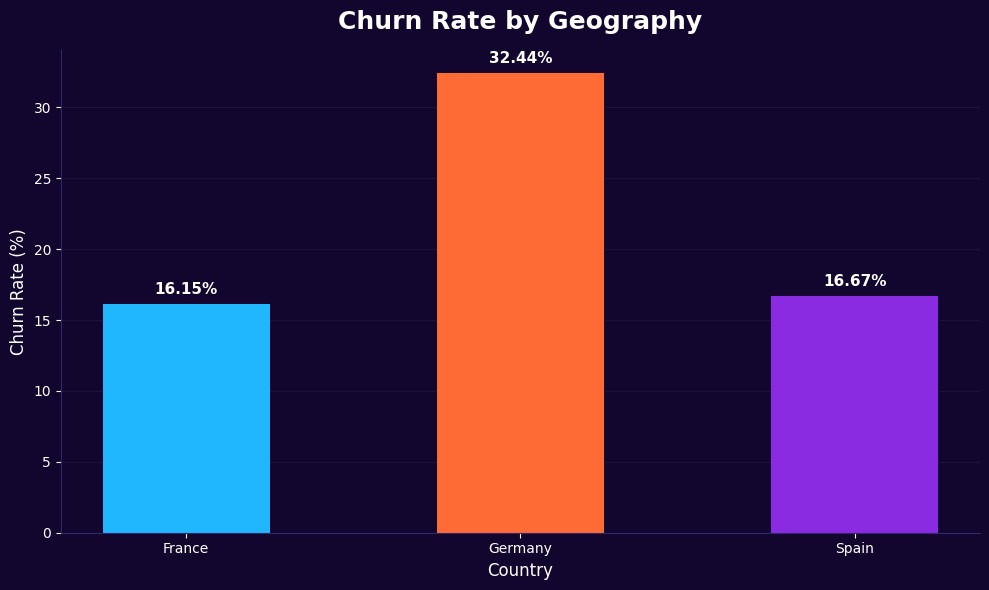

In [ ]:
geo_churn = df2.groupby('Geography')['Exited'].mean() * 100

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.bar(
    geo_churn.index,
    geo_churn.values,
    color=['#20B7FF','#FF6B35','#8A2BE2'],
    width=0.5
)

# Gridlines behind bars
ax.set_axisbelow(True)

ax.grid(
    axis='y',
    linestyle='-',
    color='#433878',
    alpha=0.20
)

# Remove unwanted borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_color('#2F296B')
ax.spines['bottom'].set_color('#2F296B')

# Titles
ax.set_title(
    'Churn Rate by Geography',
    fontsize=18,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Country', fontsize=12)
ax.set_ylabel('Churn Rate (%)', fontsize=12)

# Data labels
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.7,
        f'{height:.2f}%',
        ha='center',
        color='white',
        fontsize=11,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

**Churn By Gender**

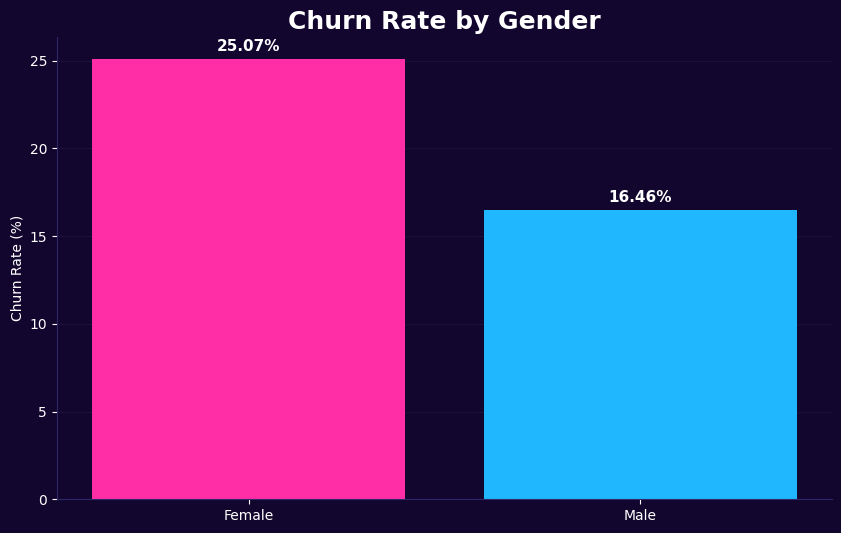

In [ ]:
gender_churn = df2.groupby('Gender')['Exited'].mean() * 100

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.bar(
    gender_churn.index.astype(str),
    gender_churn.values,
    color=['#FF2DA6', '#20B7FF']
)

ax.set_axisbelow(True)

ax.grid(
    axis='y',
    color='#433878',
    alpha=0.20
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_color('#2F296B')
ax.spines['bottom'].set_color('#2F296B')

plt.title('Churn Rate by Gender', fontsize=18, fontweight='bold')
plt.ylabel('Churn Rate (%)')

for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        h + 0.5,
        f'{h:.2f}%',
        ha='center',
        color='white',
        fontsize=11,
        fontweight='bold'
    )

plt.show()

**Churn as per AgeGroup**

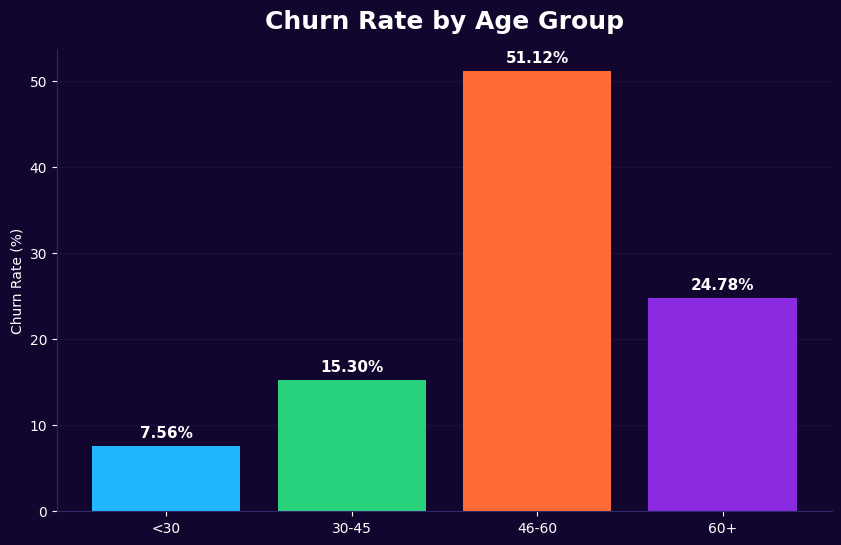

In [ ]:
age_churn = (df2.groupby('AgeGroup')['Exited']
             .mean()
             .reindex(['<30', '30-45', '46-60', '60+']) * 100)

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.bar(
    age_churn.index.astype(str),
    age_churn.values,
    color=['#20B7FF', '#28D17C', '#FF6B35', '#8A2BE2']
)

ax.set_axisbelow(True)

ax.grid(
    axis='y',
    color='#433878',
    alpha=0.20
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_color('#2F296B')
ax.spines['bottom'].set_color('#2F296B')

plt.title(
    'Churn Rate by Age Group',
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.ylabel('Churn Rate (%)')

for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        h + 1,
        f'{h:.2f}%',
        ha='center',
        color='white',
        fontsize=11,
        fontweight='bold'
    )

plt.show()

**Active vs Inactive Members**

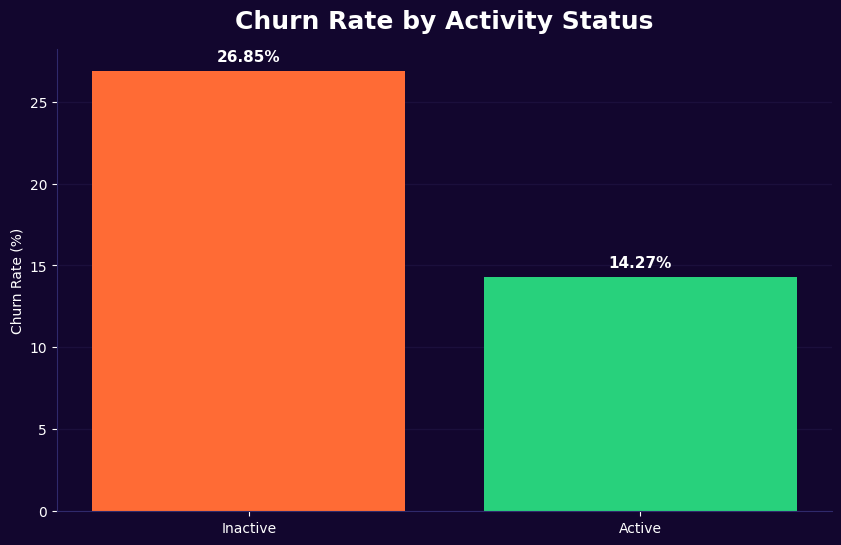

In [ ]:
active_churn = df2.groupby('IsActiveMember')['Exited'].mean() * 100

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.bar(
    ['Inactive', 'Active'],
    active_churn.values,
    color=['#FF6B35', '#28D17C']
)

ax.set_axisbelow(True)

ax.grid(
    axis='y',
    color='#433878',
    alpha=0.20
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_color('#2F296B')
ax.spines['bottom'].set_color('#2F296B')

plt.title(
    'Churn Rate by Activity Status',
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.ylabel('Churn Rate (%)')

for bar in bars:
    h = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        h + 0.6,
        f'{h:.2f}%',
        ha='center',
        color='white',
        fontsize=11,
        fontweight='bold'
    )

plt.show()

**Credit Score Band Churn Analysis**

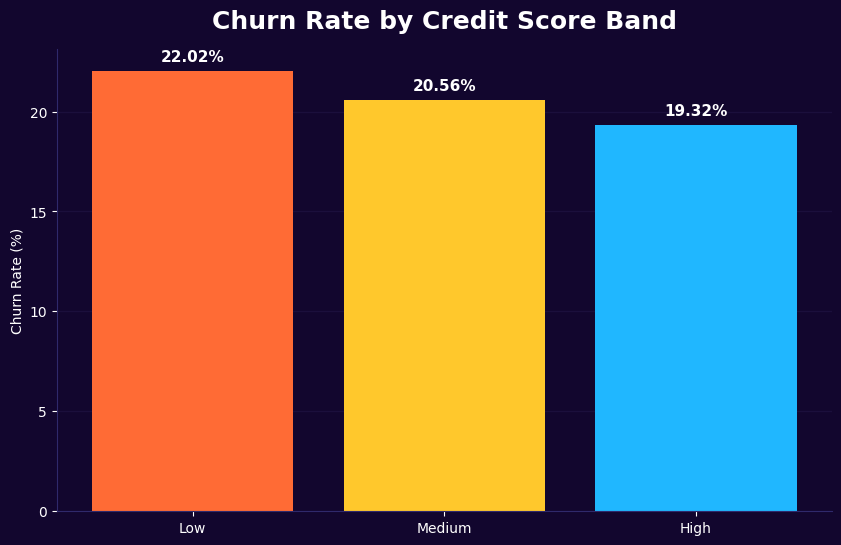

In [ ]:
credit_churn = df2.groupby('CreditScoreBand')['Exited'].mean() * 100

credit_churn = credit_churn.reindex(['Low', 'Medium', 'High'])

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.bar(
    credit_churn.index,
    credit_churn.values,
    color=['#FF6B35', '#FFC82C', '#20B7FF']
)

ax.set_axisbelow(True)

ax.grid(
    axis='y',
    color='#433878',
    alpha=0.20
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_color('#2F296B')
ax.spines['bottom'].set_color('#2F296B')

plt.title(
    'Churn Rate by Credit Score Band',
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.ylabel('Churn Rate (%)')

for bar in bars:
    h = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        h + 0.5,
        f'{h:.2f}%',
        ha='center',
        color='white',
        fontsize=11,
        fontweight='bold'
    )

plt.show()

Balance segment	Churn rate ,High	23.95%
 ,Low	34.67%
 ,Zero	13.82%

**Tenure Group Churn Analysis**

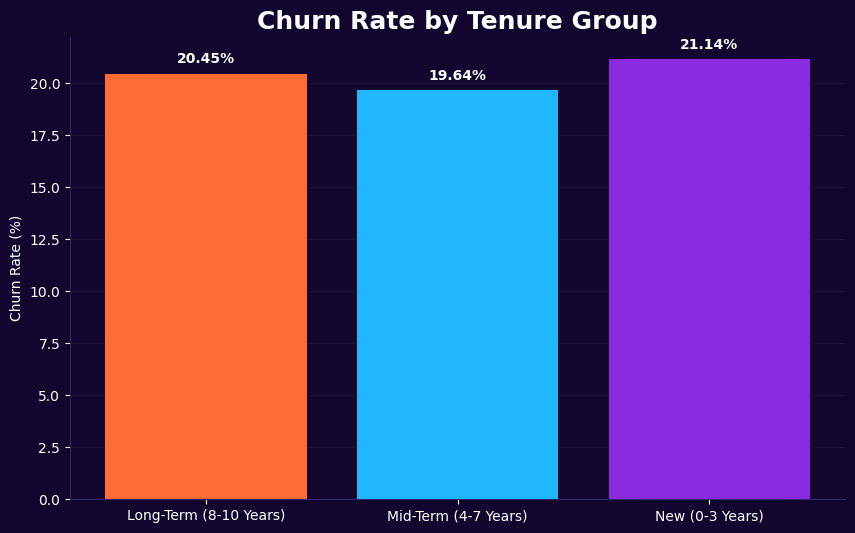

In [ ]:
tenure_churn = df2.groupby('TenureGroup')['Exited'].mean() * 100

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.bar(
    tenure_churn.index,
    tenure_churn.values,
    color=['#FF6B35', '#20B7FF', '#8A2BE2']
)

ax.set_axisbelow(True)

ax.grid(axis='y', color='#433878', alpha=0.20)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.title(
    'Churn Rate by Tenure Group',
    fontsize=18,
    fontweight='bold'
)

plt.ylabel('Churn Rate (%)')

for bar in bars:
    h = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        h + 0.5,
        f'{h:.2f}%',
        ha='center',
        color='white',
        fontweight='bold'
    )

plt.show()

**Product-wise Churn**

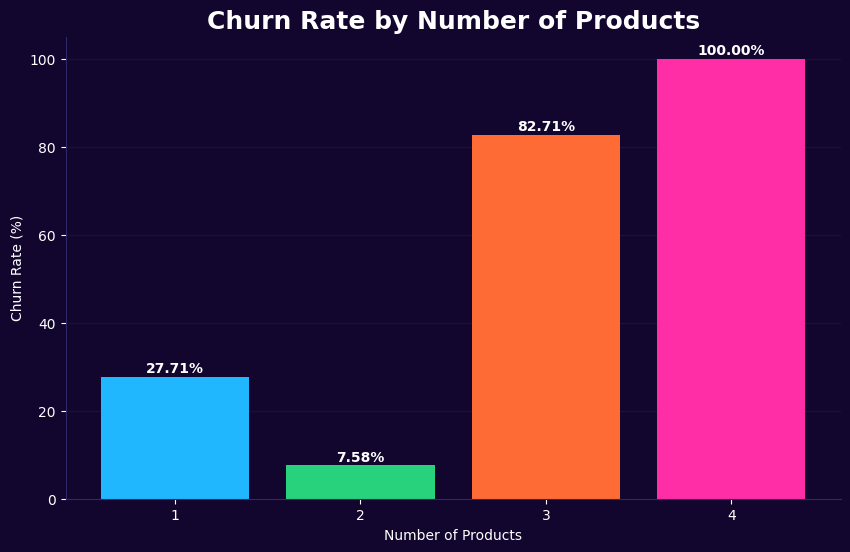

In [ ]:
product_churn = df2.groupby('NumOfProducts')['Exited'].mean() * 100

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.bar(
    product_churn.index.astype(str),
    product_churn.values,
    color=['#20B7FF','#28D17C','#FF6B35','#FF2DA6']
)

ax.set_axisbelow(True)

ax.grid(axis='y', color='#433878', alpha=0.20)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.title(
    'Churn Rate by Number of Products',
    fontsize=18,
    fontweight='bold'
)

plt.xlabel('Number of Products')
plt.ylabel('Churn Rate (%)')

for bar in bars:
    h = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        h+1,
        f'{h:.2f}%',
        ha='center',
        color='white',
        fontweight='bold'
    )

plt.show()

**Balance Segment Churn**

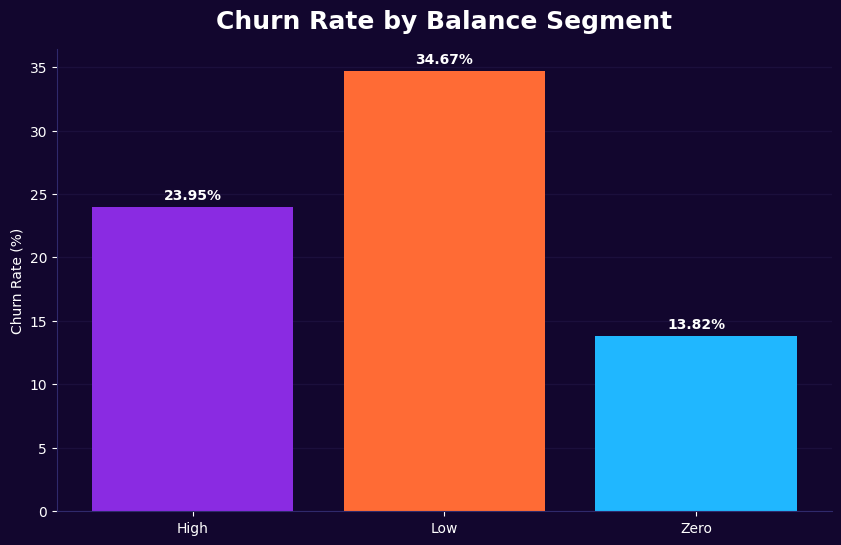

In [ ]:
balance_churn = df2.groupby('BalanceSegment')['Exited'].mean() * 100

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.bar(
    balance_churn.index,
    balance_churn.values,
    color=['#8A2BE2','#FF6B35','#20B7FF']
)

ax.set_axisbelow(True)

ax.grid(axis='y', color='#433878', alpha=0.20)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.title(
    'Churn Rate by Balance Segment',
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.ylabel('Churn Rate (%)')

for bar in bars:
    h = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        h+0.6,
        f'{h:.2f}%',
        ha='center',
        color='white',
        fontweight='bold'
    )

plt.show()

**High Value Customer Churn**

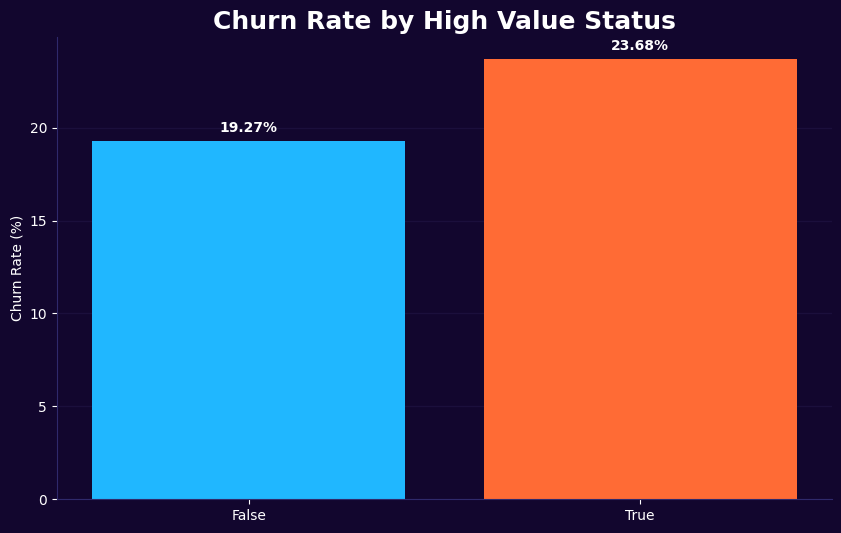

In [ ]:
hv_churn = df2.groupby('HighValue')['Exited'].mean() * 100

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.bar(
    hv_churn.index.astype(str),
    hv_churn.values,
    color=['#20B7FF', '#FF6B35']
)

ax.set_axisbelow(True)

ax.grid(
    axis='y',
    color='#433878',
    alpha=0.20
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.title(
    'Churn Rate by High Value Status',
    fontsize=18,
    fontweight='bold'
)

plt.ylabel('Churn Rate (%)')

for bar in bars:
    h = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        h + 0.5,
        f'{h:.2f}%',
        ha='center',
        color='white',
        fontweight='bold'
    )

plt.show()

**HeatMap For Better Understanding about Geaography and Agegroup**

In [ ]:
heatmap_data = df2.pivot_table(
    values='Exited',
    index='Geography',
    columns='AgeGroup',
    aggfunc='mean'
) * 100

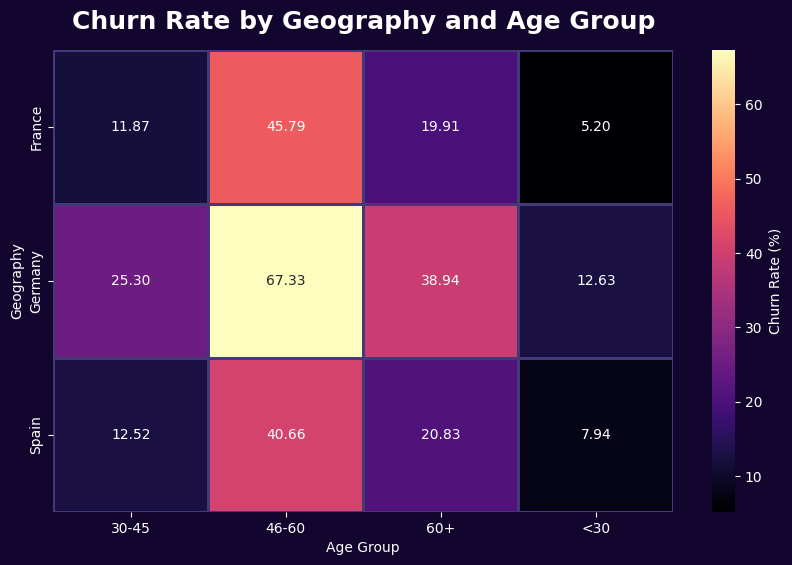

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='magma',
    linewidths=1,
    linecolor='#433878',
    cbar_kws={'label': 'Churn Rate (%)'}
)

plt.title(
    'Churn Rate by Geography and Age Group',
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.xlabel('Age Group')
plt.ylabel('Geography')

plt.show()

In [ ]:
df2.to_csv('customer_churn_final.csv', index=False)

In [ ]:
from google.colab import files
files.download('customer_churn_final.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Export Notebook Code to a Single Python File